How does an unmodelled spatially uniform eastward or northward current bias parameter recovery?

SOLO uses the circular control from `solo_idealised_tests_updated.ipynb` (cell 3).
DOPPIO and LATTE use the exact noncircular control from
`doppio_idealised_tests_updated.ipynb` (cell 3) and `latte_idealised_tests.ipynb`
(cell 2), under `/srv/scratch/z5297792/UNSW-MRes/MRes/MOCA_PAPER/final_ESP_paper_notebooks`.
`rc3_validation.load_backend` selects the original function definitions without
executing notebook analysis cells: `doppio` and `out_core_param_fit` from the
DOPPIO notebook; `latte` and `out_core_param_fit` from the LATTE notebook;
`solo` and `out_core_param_fit` from the SOLO notebook.
It reuses `unit_det`, `gaussian_vel_reconstruction`, `tangential_velocity`,
`psi_params`, and `axis_ratio_from_Q` from the sibling `../../modules/utils.py`.
No inversion objectives, initialisation rules, bounds or stopping rules are changed.
Source paths, SHA256 hashes, configuration and package versions are saved with results.
SciPy call observers forward identical arguments and retain original returns, exposing
convergence and the original outer solver's otherwise silent fallback; execution is sequential.

Both truth eddies have centre $(0,0)$ m, $R_c=85\,000$ m, $\psi_0=250\,000$ m²/s,
For DOPPIO/LATTE, $Q=\left[\begin{smallmatrix}1&0.4\\0.4&1\end{smallmatrix}\right]/\sqrt{0.84}$,
$\alpha=\sqrt{7/3}\approx1.528$, major axis 135° anticlockwise from east. For SOLO, $Q=I$ and $\alpha=1$;
orientation is undefined and shape is fixed, not estimated.
The conventions are $u=\partial_y\psi$, $v=-\partial_x\psi$,
$\Omega=-2\psi_0/R_c^2$, and centre vorticity $\zeta_0=\Omega\,\mathrm{tr}(Q)$.
$R_c$ is the Gaussian scale; normalised tangential speed peaks at $\rho=R_c/\sqrt2$.
The original $\psi_0=250$ is in km·m/s. The adapter converts SI inputs to the
notebooks' km / m/s fitting units and converts fitted quantities back to SI.
$U_{\rm ref}$ is the maximum true full-field **vector speed**, evaluated with the
original velocity function at its analytic peak **for each truth shape**: circular
SOLO and elliptical DOPPIO/LATTE have different reference speeds. Each reference
is fixed across all conditions and shared between the two experiments. Trial tables
and provenance record the shape and reference speed explicitly.

SOLO uses the manuscript P1/L2 eastward transect: x=−70…70 km, y=20 km,
with $N$ total observations. Along-track positions are translated to Cartesian
coordinates using the same convention as the original notebook. Its original call
leaves `core_thresh=30000` in the km-coordinate function, so this threshold covers
the full 140 km transect; it is not a newly imposed 30 km window. This reproduces
the manuscript notebook call exactly, with no retuning across conditions.
SOLO aspect-ratio errors and incremental shape changes are unavailable (`NaN`),
because its circular shape is prescribed rather than recovered.
DOPPIO uses the manuscript P1/L2 cross at (10,10) km, each transect spanning ±30 km;
$N$ is **per transect**, with one shared observation at the intersection ($2N-1$ unique).
The odd counts retain that exact intersection. LATTE uses a reproducible scattered
extension of the idealised ±50 km square footprint: $N$ **total** points, including
four fixed corners plus nested iid uniform points. Coverage/convex hull and point
locations are fixed across perturbations; point-cloud variability is not replicated.
The counts therefore do not constitute a matched observation-budget or identical-truth comparison.
All sampled velocities enter both stages, as in these idealised notebooks; no
truth-centred window or additional data is supplied to the fit. Original outer caps:
SOLO/DOPPIO $10^6$ km; LATTE default $10^5$ km (post-fit checks, not optimisation bounds).
No explicit background term is fitted.

The original cubic/affine inner fits approximate a Gaussian core. Small nonzero
clean bias is expected; LATTE's shape bias can be appreciable and is reported.
A fit is accepted only with actual optimiser convergence, finite parameters,
positive radius and symmetric positive-definite $Q$ with determinant one.
There is **no error-based rejection**. Failed fits retain statuses and attempted
parameters; medians use accepted full fits and their corresponding acceptance
fractions are displayed. Orientation is not scored. These are controlled sensitivity
tests, not measured observational uncertainty or an algorithm ranking.

Fixed N=101 and the identical geometry used at N=101 in the noise experiment. Add a constant vector with speed 0, 5, 10, 20, 30 or 50% of $U_{\rm ref}$, directed eastward or northward. No noise, replication or background subtraction. Both directions include the identical zero-current control. The figure distinguishes total absolute errors against truth from incremental displacement and signed radius/shape changes against each method’s clean fit. This tests uniform flow, not shear.

In [1]:
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/rc3-mpl")
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Support launching either here or at the UNSW-PhD repository root.
WORKDIR = Path.cwd()
if not (WORKDIR / "rc3_validation.py").is_file():
    WORKDIR = WORKDIR / "esp/os_paper_additional_tests"
sys.path.insert(0, str(WORKDIR.resolve()))
from rc3_validation import (Config, run_noise_sampling, run_background_flow,
                            summarize, interpretation, save_results)
from rc3_plotting import plot_noise_sampling, plot_background_flow

CONFIG = Config()  # immutable settings; edit source_root here if the originals move
OUTPUT = WORKDIR / "results"


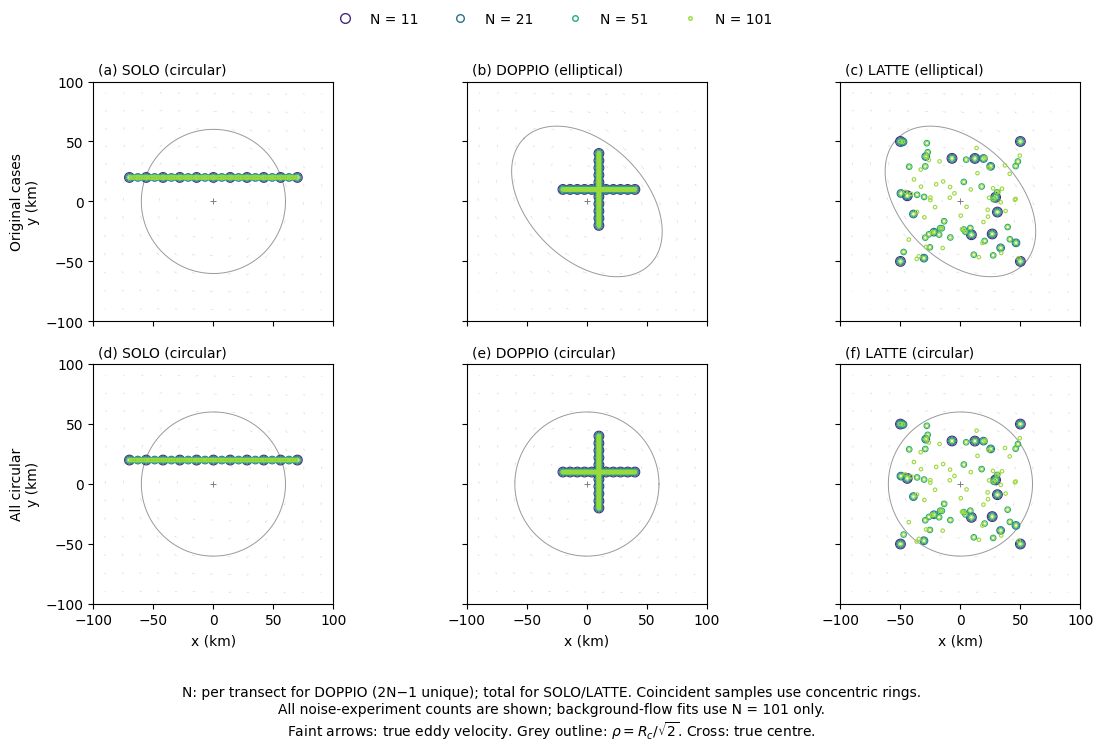

In [2]:
# Sampling overview: original truth assignments above, all circular below.
# Ring colours identify all counts; shared locations are not shifted.
from rc3_plotting import plot_sampling_layout

assert not plt.get_fignums()
sampling_fig = plot_sampling_layout(CONFIG)
OUTPUT.mkdir(parents=True, exist_ok=True)
sampling_fig.savefig(OUTPUT / "rc3_background_flow_layout.pdf", bbox_inches="tight")
sampling_fig.savefig(OUTPUT / "rc3_background_flow_layout.png", dpi=300, bbox_inches="tight")
display(sampling_fig)
plt.close(sampling_fig)

In [3]:
results = run_background_flow(CONFIG)
save_results(results, OUTPUT, "rc3_background_flow")
summary = summarize(results)

In [10]:
for method, truth in results.attrs["truth_by_method"].items():
    shape = "circular" if method == "SOLO" else "elliptical"
    display(Markdown(f"{method} ({shape}): Rc={truth['rc_m']/1000:.0f} km; "
                     f"alpha={truth['alpha']:.6f}; Omega={truth['omega_s']:.6g} s⁻¹; "
                     f"centre vorticity={truth['vorticity_s']:.6g} s⁻¹; "
                     f"U_ref={truth['u_ref_m_s']:.6f} m/s."))
print(f"Accepted {results.success.sum()}/{len(results)} full fits.")
print(results.groupby(["method", "status"]).size().to_string())
# Complete tidy trials (including Q and fitted parameters) and summary remain in memory.
# display(summary.round(3))

SOLO (circular): Rc=85 km; alpha=1.000000; Omega=-6.92042e-05 s⁻¹; centre vorticity=-0.000138408 s⁻¹; U_ref=2.522835 m/s.

DOPPIO (elliptical): Rc=85 km; alpha=1.527525; Omega=-6.92042e-05 s⁻¹; centre vorticity=-0.000151016 s⁻¹; U_ref=3.118050 m/s.

LATTE (elliptical): Rc=85 km; alpha=1.527525; Omega=-6.92042e-05 s⁻¹; centre vorticity=-0.000151016 s⁻¹; U_ref=3.118050 m/s.

Accepted 36/36 full fits.
method  status
DOPPIO  ok        12
LATTE   ok        12
SOLO    ok        12


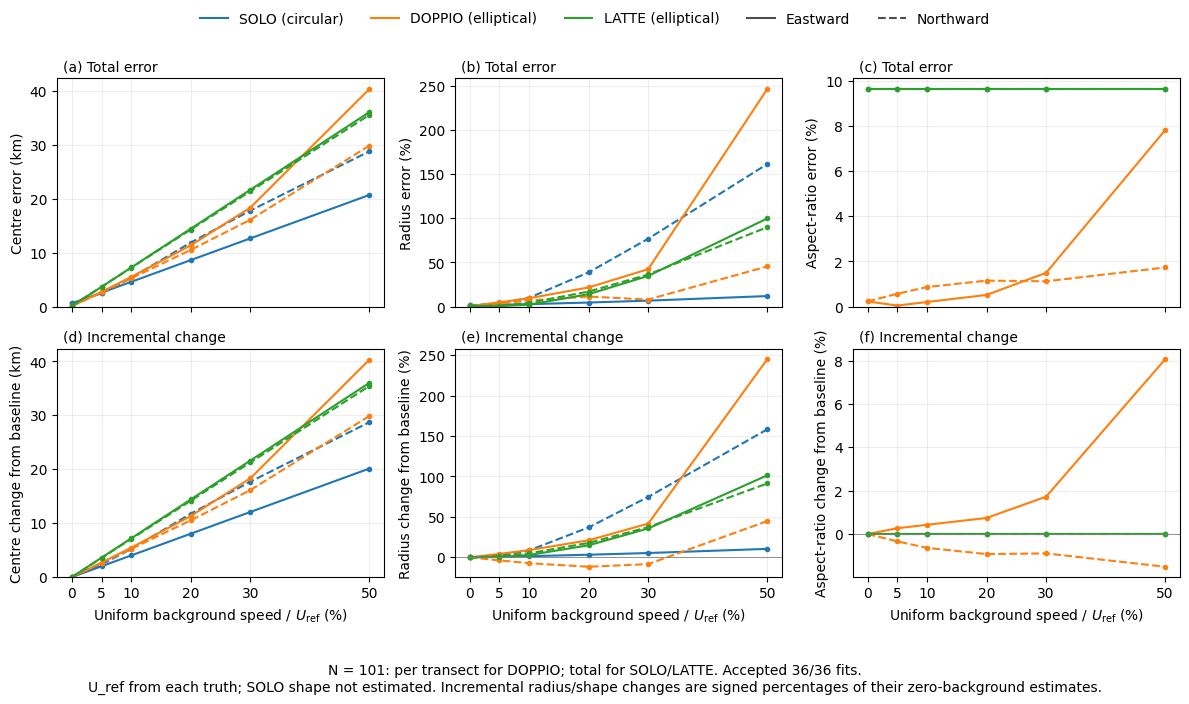

In [5]:
assert not plt.get_fignums(), "The experiment must create exactly one Figure."
fig = plot_background_flow(results, CONFIG)
assert plt.get_fignums() == [fig.number]
fig.savefig(OUTPUT / "rc3_background_flow.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "rc3_background_flow.png", dpi=300, bbox_inches="tight")
display(fig)
plt.close(fig)  # prevent a duplicate automatic display

In [6]:
display(Markdown(interpretation(results)))

- SOLO, N=101 clean baseline: centre 0.561 km; radius 1.29% absolute error; shape fixed circular (not estimated).
- DOPPIO, N=101 clean baseline: centre 0.063 km; radius 0.49% absolute error; aspect ratio 0.23% absolute error.
- LATTE, N=101 clean baseline: centre 0.115 km; radius 0.72% absolute error; aspect ratio 9.64% absolute error.
- Accepted 36/36 fits; failure statuses: none. Acceptance requires solver convergence and physical Q, with no accuracy threshold.
- At the largest tested background: SOLO/eastward: 20.69 km total, 20.13 km incremental centre displacement; SOLO/northward: 28.78 km total, 28.72 km incremental centre displacement; DOPPIO/eastward: 40.32 km total, 40.30 km incremental centre displacement; DOPPIO/northward: 29.83 km total, 29.86 km incremental centre displacement; LATTE/eastward: 36.05 km total, 36.01 km incremental centre displacement; LATTE/northward: 35.54 km total, 35.43 km incremental centre displacement.

These deterministic uniform-current tests do not test shear, noise, time dependence or real-data robustness. The original inner-core approximations cause nonzero clean bias, especially LATTE shape bias; the simulations are sensitivity tests, not exact Gaussian-parameter estimators.

Additional comparison: all three methods applied to the same circular eddy.

The original experiment and figure above are retained. Here only the truth for
DOPPIO and LATTE changes to the manuscript's circular control ($Q=I$, $\alpha=1$).
All three methods share the same centre, $R_c=85$ km, $\psi_0=250\,000$ m²/s
and fixed full-field reference speed. Sampling geometries, sample counts,
replicates, noise streams, fitting functions and tuning remain the same as above.
The circular and original experiments use paired standard-normal draws; physical
noise amplitudes scale with the corresponding truth's reference speed. SOLO's
trials are consequently identical between comparisons.

DOPPIO and LATTE retain their unrestricted shape fits: aspect-ratio error now
measures **spurious ellipticity** relative to 1. SOLO shape remains prescribed,
so its shape errors are unavailable. Orientation is undefined for the circular
truth and is not scored. Different method geometries and observation budgets
still prevent interpreting this as a controlled algorithm ranking.
Additional outputs use a separate `_circular` filename suffix.

In [11]:
from dataclasses import replace

CIRCULAR_CONFIG = replace(CONFIG, all_circular=True)
circular_results = run_background_flow(CIRCULAR_CONFIG)
save_results(circular_results, OUTPUT, "rc3_background_flow_circular")
circular_summary = summarize(circular_results)
print(f"Circular control: accepted {circular_results.success.sum()}/{len(circular_results)} fits.")
print(circular_results.groupby(["method", "status"]).size().to_string())
print("Common U_ref (m/s):", circular_results.u_ref_m_s.iloc[0])
# display(circular_summary.round(3))

Circular control: accepted 36/36 fits.
method  status
DOPPIO  ok        12
LATTE   ok        12
SOLO    ok        12
Common U_ref (m/s): 2.5228349557667844


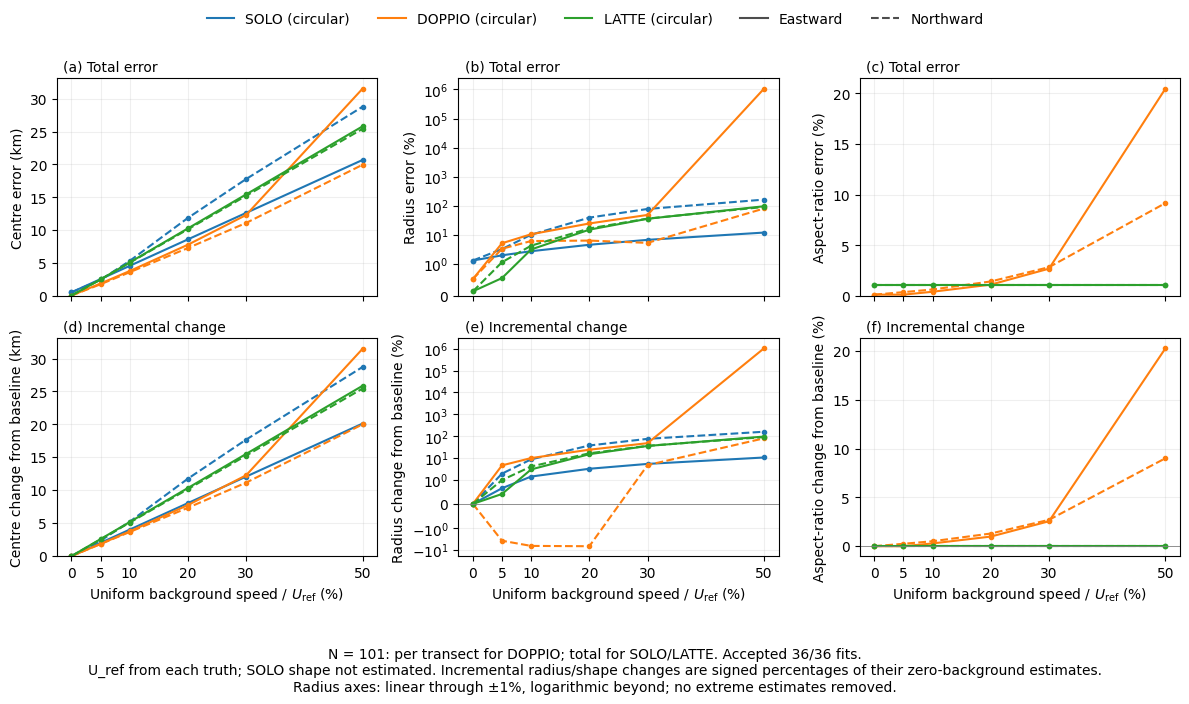

- SOLO, N=101 clean baseline: centre 0.561 km; radius 1.29% absolute error; shape fixed circular (not estimated).
- DOPPIO, N=101 clean baseline: centre 0.066 km; radius 0.53% absolute error; aspect ratio 0.14% absolute error.
- LATTE, N=101 clean baseline: centre 0.074 km; radius 0.14% absolute error; aspect ratio 1.05% absolute error.
- Accepted 36/36 fits; failure statuses: none. Acceptance requires solver convergence and physical Q, with no accuracy threshold.
- At the largest tested background: SOLO/eastward: 20.69 km total, 20.13 km incremental centre displacement; SOLO/northward: 28.78 km total, 28.72 km incremental centre displacement; DOPPIO/eastward: 31.53 km total, 31.48 km incremental centre displacement; DOPPIO/northward: 19.96 km total, 20.01 km incremental centre displacement; LATTE/eastward: 25.80 km total, 25.87 km incremental centre displacement; LATTE/northward: 25.41 km total, 25.44 km incremental centre displacement.

These deterministic uniform-current tests do not test shear, noise, time dependence or real-data robustness. The original inner-core approximations cause nonzero clean bias, especially LATTE shape bias; the simulations are sensitivity tests, not exact Gaussian-parameter estimators.

The largest circular-case fitted radius is 906,274 km (DOPPIO; background fraction 0.5, eastward; noise fraction 0). This extreme estimate is retained: solver convergence does not establish useful radius recovery. Radius plots use a logarithmic scale beyond 1% error.

In [8]:
assert not plt.get_fignums(), "Close the previous figure before the circular comparison."
circular_fig = plot_background_flow(circular_results, CIRCULAR_CONFIG)
assert plt.get_fignums() == [circular_fig.number]
circular_fig.savefig(OUTPUT / "rc3_background_flow_circular.pdf", bbox_inches="tight")
circular_fig.savefig(OUTPUT / "rc3_background_flow_circular.png", dpi=300, bbox_inches="tight")
display(circular_fig)
plt.close(circular_fig)
display(Markdown(interpretation(circular_results)))